# Universidad del Valle de Guatemala
## CC3084 - Data Science
### Laboratorio 1 — Series de Tiempo

#### Cristian Tunchez - 231359  
#### Nadissa Vela - 23764

## Categoría 3.b.iv — Fronteras (top 3 por total acumulado)

**Ejercicio 4**, aplicado a las tres series mensuales de la categoría
**Frontera**: **01 La Aurora** (aeropuerto internacional), **07 Valle Nuevo**
(frontera terrestre con El Salvador) y **09 San Cristóbal** (frontera
terrestre con Honduras) — seleccionadas en `02_preparacion_series.ipynb` por
ser las tres fronteras con mayor número acumulado de visitantes 2009–jun 2026,
y elegidas en lugar de *Vías de ingreso* porque esa categoría tiene un corte
de cobertura sin datos desde 2017 en la vía Marítima (ver notebook 02).

Igual que en `04_series_regiones.ipynb`, el pipeline completo del ejercicio 4
vive en `src/ts_utils.py` (`analizar_serie_completa`) para no repetir código.

## Configuración del entorno

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import ts_utils as tsu

pd.set_option("display.max_columns", 40)
panel = pd.read_csv("../data/processed/series_mensuales.csv", parse_dates=["fecha"])

def cargar(nombre_serie):
    sub = panel[panel["serie"] == nombre_serie].sort_values("fecha")
    s = sub.set_index("fecha")["viajeros"].asfreq("MS")
    train = s[sub.set_index("fecha")["conjunto"] == "train"]
    test = s[sub.set_index("fecha")["conjunto"] == "test"]
    return train, test

SERIES_FRONTERA = {
    "01 La Aurora":      "frontera_aurora",
    "07 Valle Nuevo":    "frontera_valle_nuevo",
    "09 San Cristóbal":  "frontera_san_cristobal",
}
print("Series de la categoría Fronteras:", list(SERIES_FRONTERA.keys()))


Series de la categoría Fronteras: ['01 La Aurora', '07 Valle Nuevo', '09 San Cristóbal']


## 1. Frontera 01 La Aurora (aeropuerto internacional)

SERIE: 01 La Aurora
Serie: 01 La Aurora
  Inicio:        2009-01
  Fin:           2026-06
  Frecuencia:    MS
  Observaciones: 210
  Faltantes:     0


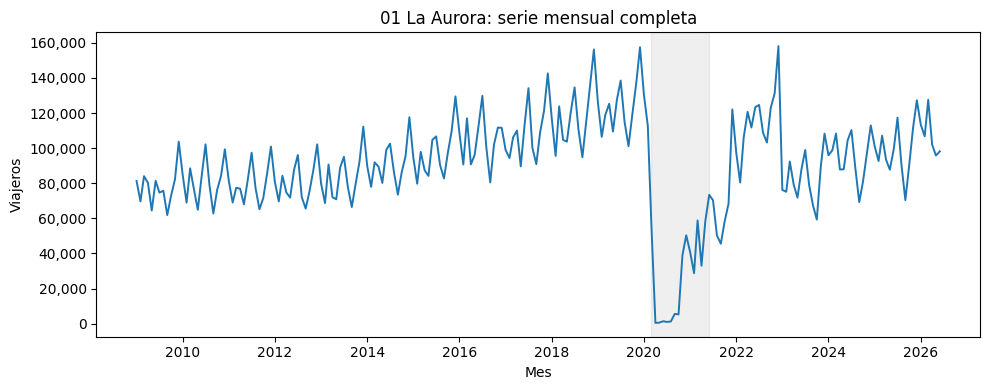

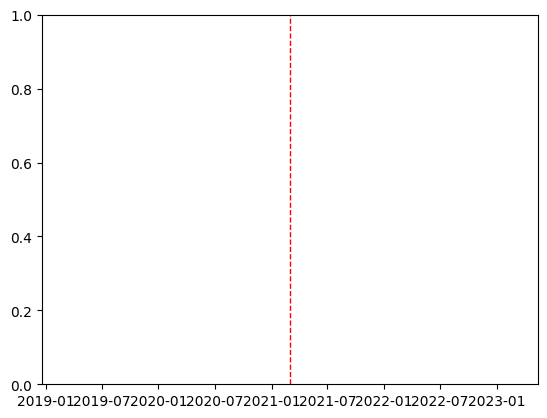

Correlación nivel medio anual vs. desviación estándar anual (sin 2020-2021): 0.89
-> Se usa descomposición multiplicative (la amplitud estacional crece con el nivel).


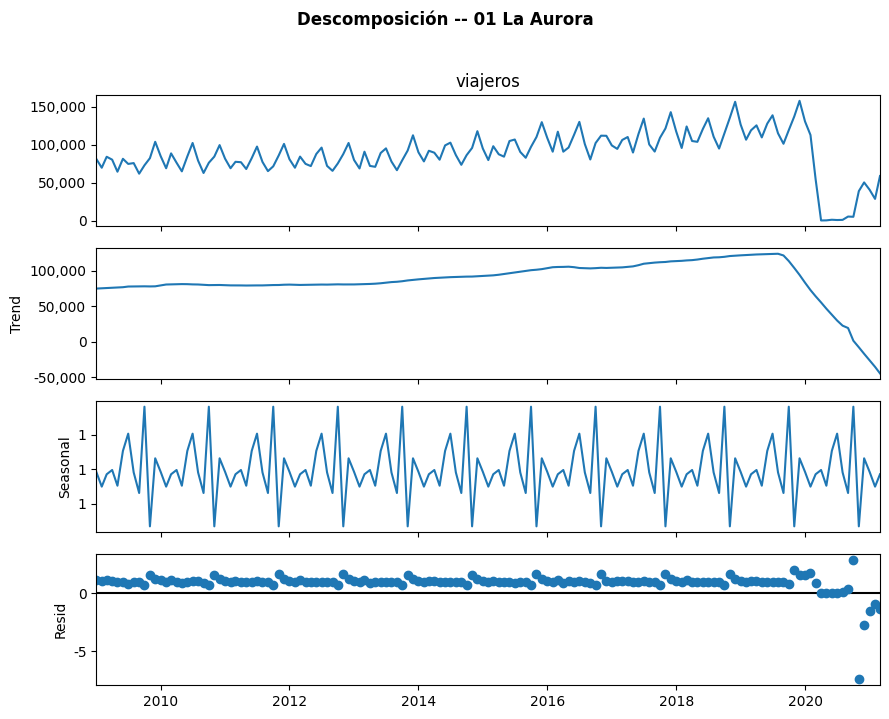

Transformación aplicada: logaritmo (np.log).

ADF sobre la serie (transformada) en nivel:
ADF (01 La Aurora): estadístico=-2.0323  p-valor=0.2726  lags usados=12  n obs=134
  Valores críticos: {'1%': np.float64(-3.48), '5%': np.float64(-2.883), '10%': np.float64(-2.578)}
  Conclusión (alpha=0.05): la serie es NO estacionaria en media.

Búsqueda de 'd' (diferenciación regular):
  d=0: ADF p-valor=0.2726
  d=1: ADF p-valor=0.0269
  -> Diferenciaciones necesarias: d=1


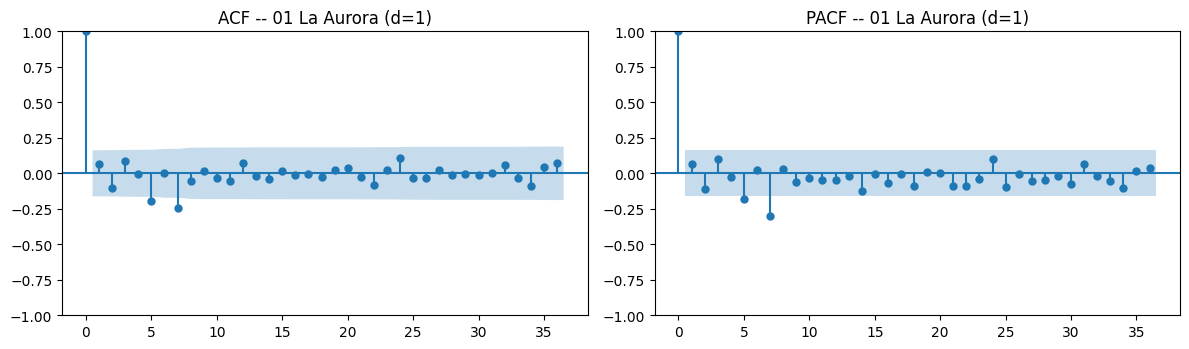


ADF tras diferenciación regular + estacional (D=1):
ADF (01 La Aurora, d+D=1(12)): estadístico=-6.2125  p-valor=0.0000  lags usados=11  n obs=122
  Valores críticos: {'1%': np.float64(-3.485), '5%': np.float64(-2.886), '10%': np.float64(-2.58)}
  Conclusión (alpha=0.05): la serie es ESTACIONARIA en media.

Elección manual (ACF/PACF): order=(1, 1, 1)  seasonal_order=(1, 1, 1, 12)
auto_arima:                 order=(3, 0, 2)  seasonal_order=(1, 0, 1, 12)


,modelo,order,seasonal_order,AIC,BIC,media_residuo,std_residuo
0,"(1, 1, 0)x(1, 1, 0, 12)","(1, 1, 0)","(1, 1, 0, 12)",194.877697,203.571217,0.036715,1.151198
1,"(0, 1, 1)x(0, 1, 1, 12)","(0, 1, 1)","(0, 1, 1, 12)",195.507121,204.200640,0.036800,1.151794
2,"(1, 1, 1)x(1, 1, 1, 12)","(1, 1, 1)","(1, 1, 1, 12)",198.265063,212.754262,0.036259,1.150394
3,"(3, 0, 2)x(1, 0, 1, 12)","(3, 0, 2)","(1, 0, 1, 12)",200.457690,227.371583,-0.004571,0.445346


Mejor ARIMA por AIC: (1, 1, 0)x(1, 1, 0, 12)


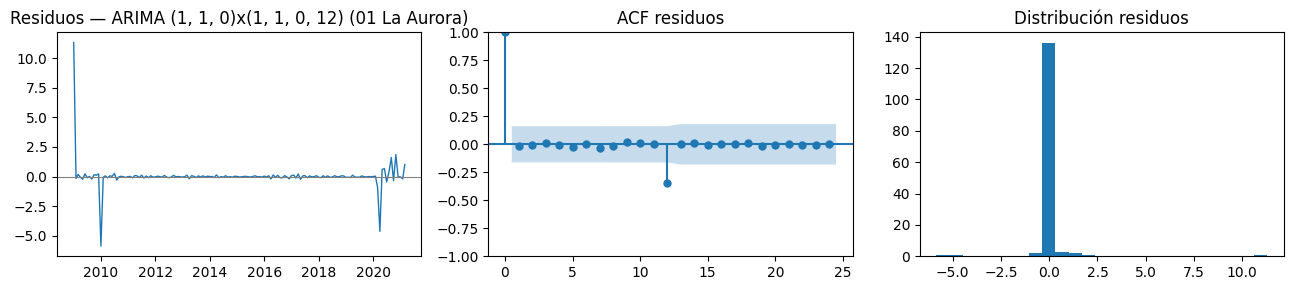

Ljung-Box (ARIMA (1, 1, 0)x(1, 1, 0, 12) (01 La Aurora)):


,lb_stat,lb_pvalue
12,20.227705,0.062899
24,20.314556,0.678755


Importing plotly failed. Interactive plots will not work.


  -> Residuos compatibles con ruido blanco (no autocorrelación).


16:24:54 - cmdstanpy - INFO - Chain [1] start processing
16:24:54 - cmdstanpy - INFO - Chain [1] done processing


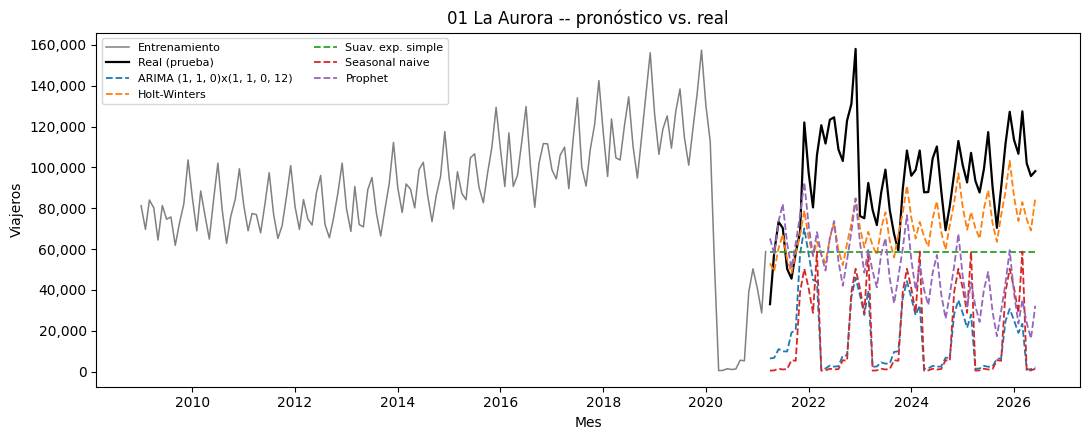

,modelo,MAE,RMSE,AIC,BIC
0,Holt-Winters,"25,156","30,237","2,734.6","2,782.5"
1,Suav. exp. simple,"36,822","42,053","2,874.8","2,880.8"
2,Prophet,"45,973","50,963",nan,nan
3,Seasonal naive,"75,518","79,321",nan,nan
4,"ARIMA (1, 1, 0)x(1, 1, 0, 12)","76,601","80,767",194.9,203.6


Mejor modelo para 01 La Aurora: Holt-Winters  (MAE=25,156, RMSE=30,237)


In [2]:
train_au, test_au = cargar("frontera_aurora")
resultado_au = tsu.analizar_serie_completa("01 La Aurora", train_au, test_au, periodo=12)


## 2. Frontera 07 Valle Nuevo (terrestre, El Salvador)

SERIE: 07 Valle Nuevo
Serie: 07 Valle Nuevo
  Inicio:        2009-01
  Fin:           2026-06
  Frecuencia:    MS
  Observaciones: 210
  Faltantes:     0


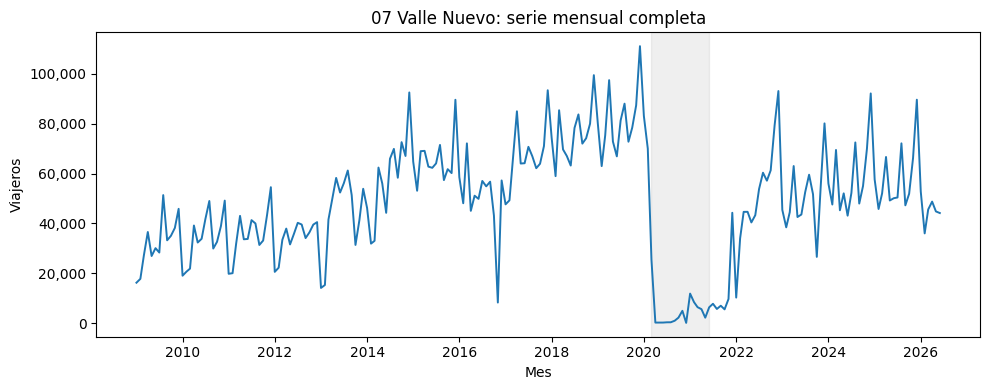

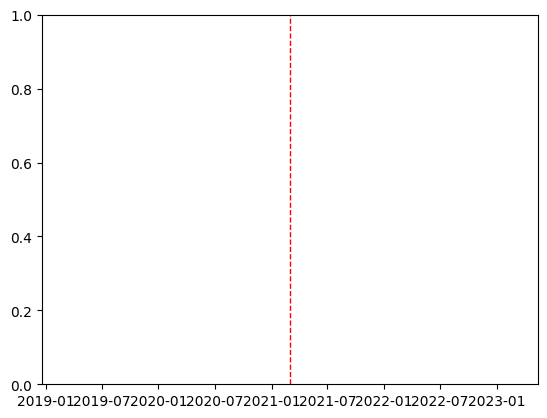

Correlación nivel medio anual vs. desviación estándar anual (sin 2020-2021): 0.31
-> Se usa descomposición multiplicative (la amplitud estacional crece con el nivel).


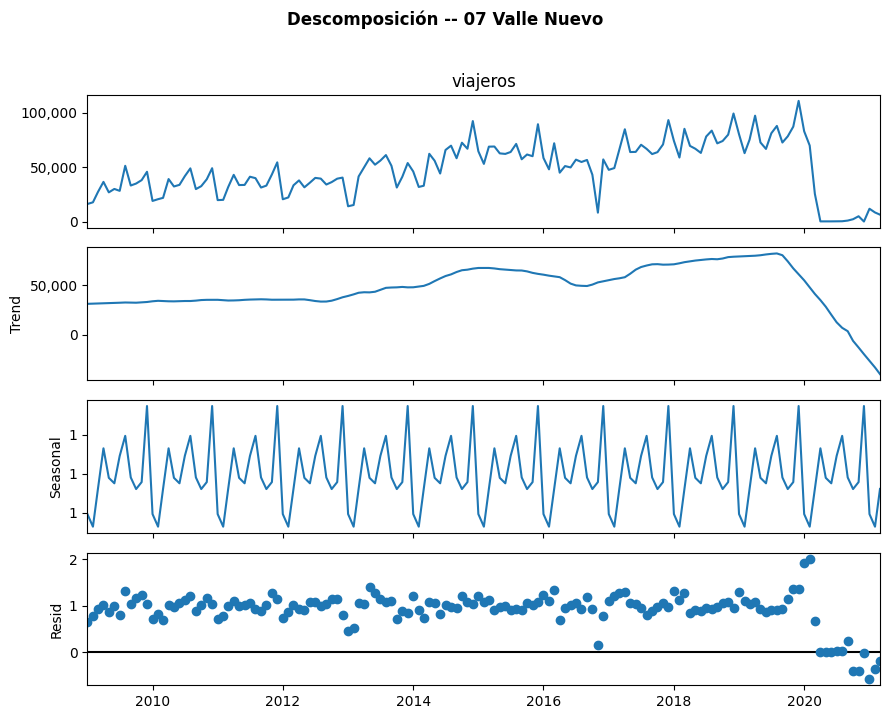

Transformación aplicada: logaritmo (np.log).

ADF sobre la serie (transformada) en nivel:
ADF (07 Valle Nuevo): estadístico=-2.2310  p-valor=0.1952  lags usados=9  n obs=137
  Valores críticos: {'1%': np.float64(-3.479), '5%': np.float64(-2.883), '10%': np.float64(-2.578)}
  Conclusión (alpha=0.05): la serie es NO estacionaria en media.

Búsqueda de 'd' (diferenciación regular):
  d=0: ADF p-valor=0.1952
  d=1: ADF p-valor=0.0000
  -> Diferenciaciones necesarias: d=1


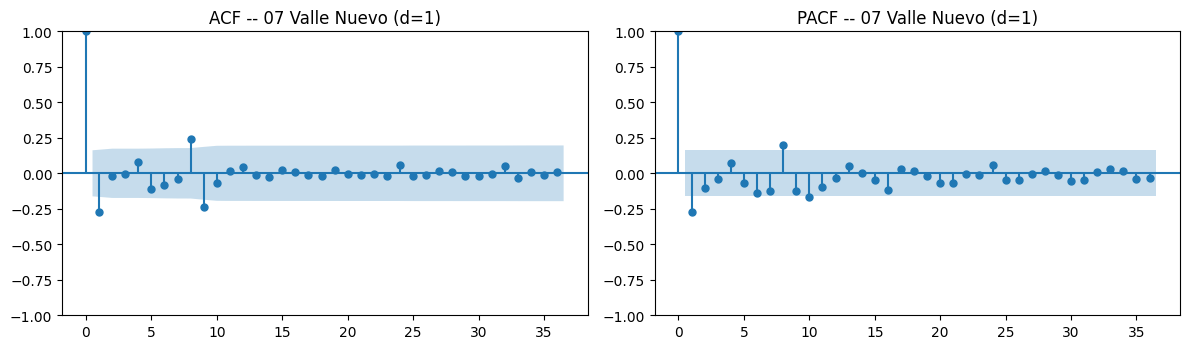


ADF tras diferenciación regular + estacional (D=1):
ADF (07 Valle Nuevo, d+D=1(12)): estadístico=-5.3086  p-valor=0.0000  lags usados=11  n obs=122
  Valores críticos: {'1%': np.float64(-3.485), '5%': np.float64(-2.886), '10%': np.float64(-2.58)}
  Conclusión (alpha=0.05): la serie es ESTACIONARIA en media.

Elección manual (ACF/PACF): order=(1, 1, 1)  seasonal_order=(1, 1, 1, 12)
auto_arima:                 order=(1, 0, 1)  seasonal_order=(0, 0, 0, 12)


,modelo,order,seasonal_order,AIC,BIC,media_residuo,std_residuo
0,"(0, 1, 1)x(0, 1, 1, 12)","(0, 1, 1)","(0, 1, 1, 12)",323.693669,332.387189,0.012351,1.200396
1,"(1, 1, 0)x(1, 1, 0, 12)","(1, 1, 0)","(1, 1, 0, 12)",324.235952,332.929471,0.015867,1.201310
2,"(1, 1, 1)x(1, 1, 1, 12)","(1, 1, 1)","(1, 1, 1, 12)",326.964736,341.453935,0.011772,1.198408
3,"(1, 0, 1)x(0, 0, 0, 12)","(1, 0, 1)","(0, 0, 0, 12)",330.235123,342.196854,0.005485,0.724980


Mejor ARIMA por AIC: (0, 1, 1)x(0, 1, 1, 12)


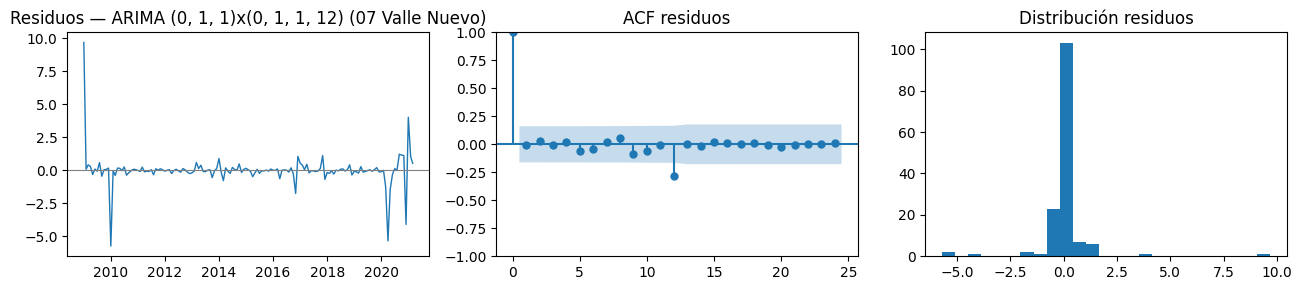

Ljung-Box (ARIMA (0, 1, 1)x(0, 1, 1, 12) (07 Valle Nuevo)):


,lb_stat,lb_pvalue
12,16.589361,0.165708
24,16.875883,0.853907


16:24:59 - cmdstanpy - INFO - Chain [1] start processing
16:24:59 - cmdstanpy - INFO - Chain [1] done processing


  -> Residuos compatibles con ruido blanco (no autocorrelación).


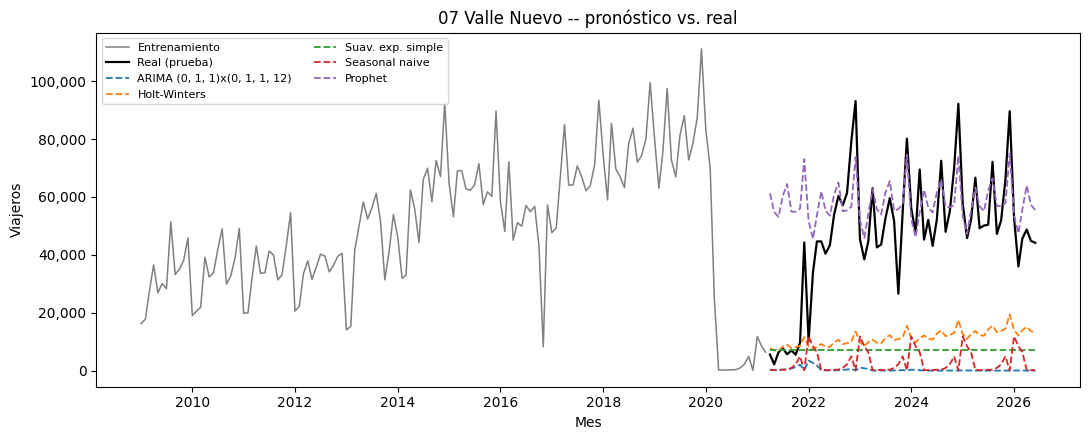

,modelo,MAE,RMSE,AIC,BIC
0,Prophet,"15,219","21,764",nan,nan
1,Holt-Winters,"36,691","41,094","2,761.7","2,809.6"
2,Suav. exp. simple,"40,770","45,663","2,809.1","2,815.1"
3,Seasonal naive,"44,707","49,661",nan,nan
4,"ARIMA (0, 1, 1)x(0, 1, 1, 12)","47,207","51,865",323.7,332.4


Mejor modelo para 07 Valle Nuevo: Prophet  (MAE=15,219, RMSE=21,764)


In [3]:
train_vn, test_vn = cargar("frontera_valle_nuevo")
resultado_vn = tsu.analizar_serie_completa("07 Valle Nuevo", train_vn, test_vn, periodo=12)


## 3. Frontera 09 San Cristóbal (terrestre, Honduras)

SERIE: 09 San Cristóbal
Serie: 09 San Cristóbal
  Inicio:        2009-01
  Fin:           2026-06
  Frecuencia:    MS
  Observaciones: 210
  Faltantes:     0


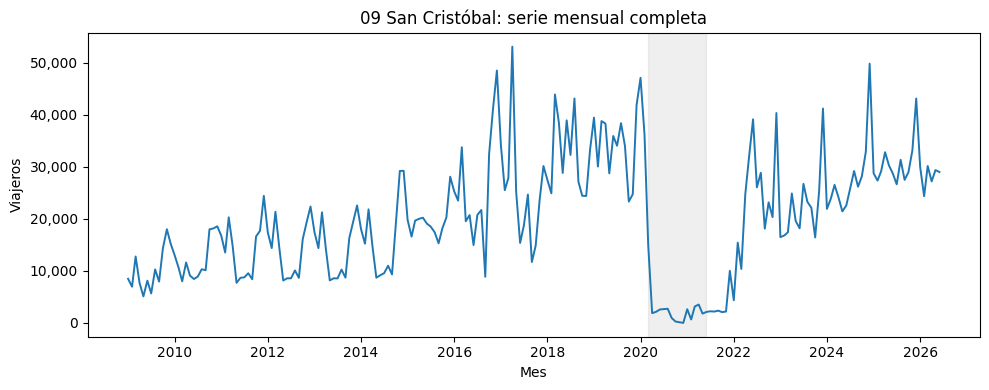

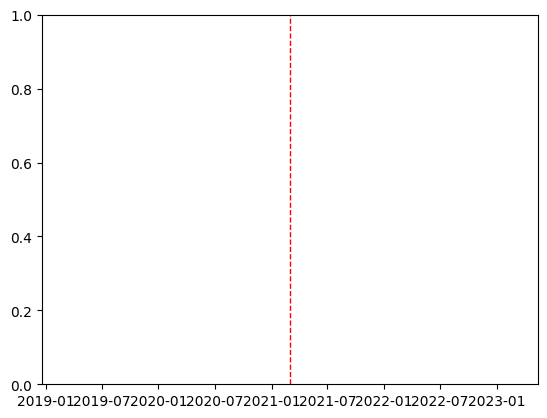

Correlación nivel medio anual vs. desviación estándar anual (sin 2020-2021): 0.53
-> Se usa descomposición multiplicative (la amplitud estacional crece con el nivel).


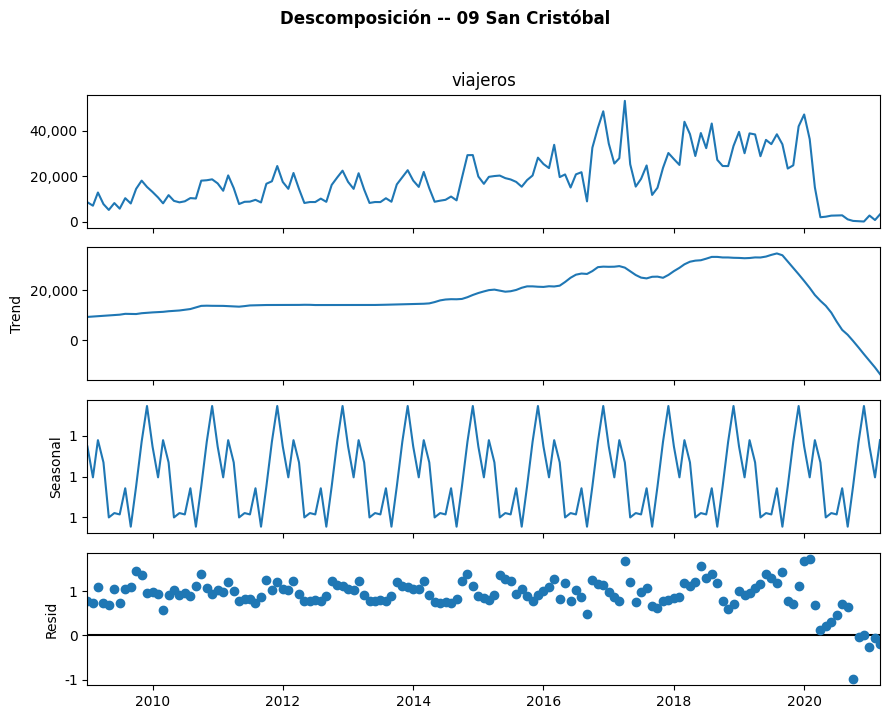

Transformación aplicada: logaritmo (np.log).

ADF sobre la serie (transformada) en nivel:
ADF (09 San Cristóbal): estadístico=-2.0799  p-valor=0.2527  lags usados=14  n obs=132
  Valores críticos: {'1%': np.float64(-3.481), '5%': np.float64(-2.884), '10%': np.float64(-2.579)}
  Conclusión (alpha=0.05): la serie es NO estacionaria en media.

Búsqueda de 'd' (diferenciación regular):
  d=0: ADF p-valor=0.2527
  d=1: ADF p-valor=0.9121
  d=2: ADF p-valor=0.0000
  -> Diferenciaciones necesarias: d=2


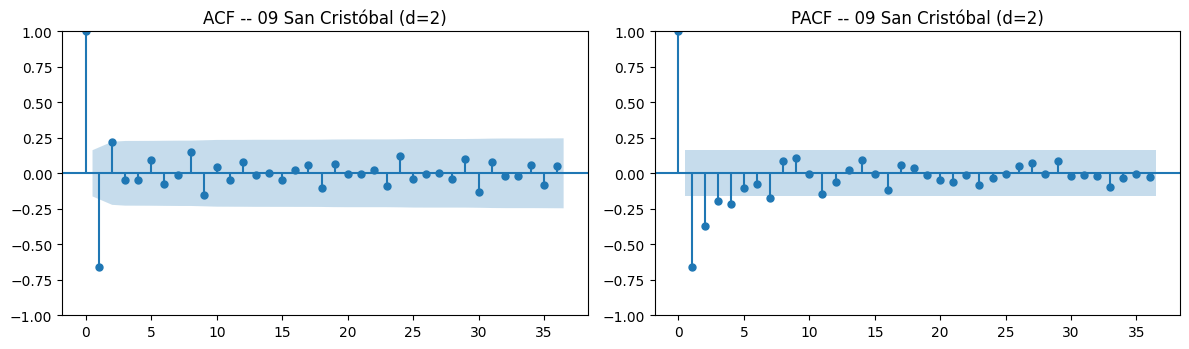


ADF tras diferenciación regular + estacional (D=1):
ADF (09 San Cristóbal, d+D=1(12)): estadístico=-4.5366  p-valor=0.0002  lags usados=12  n obs=120
  Valores críticos: {'1%': np.float64(-3.486), '5%': np.float64(-2.886), '10%': np.float64(-2.58)}
  Conclusión (alpha=0.05): la serie es ESTACIONARIA en media.

Elección manual (ACF/PACF): order=(1, 2, 1)  seasonal_order=(1, 1, 1, 12)
auto_arima:                 order=(3, 0, 4)  seasonal_order=(2, 0, 0, 12)


,modelo,order,seasonal_order,AIC,BIC,media_residuo,std_residuo
0,"(3, 0, 4)x(2, 0, 0, 12)","(3, 0, 4)","(2, 0, 0, 12)",260.032058,292.926817,0.003713,0.535056
1,"(1, 2, 1)x(1, 1, 1, 12)","(1, 2, 1)","(1, 1, 1, 12)",264.807852,279.259597,0.020921,1.143355
2,"(0, 2, 1)x(0, 1, 1, 12)","(0, 2, 1)","(0, 1, 1, 12)",281.013738,289.684786,0.025993,1.168097
3,"(1, 2, 0)x(1, 1, 0, 12)","(1, 2, 0)","(1, 1, 0, 12)",314.693097,323.364144,0.038384,1.221664


Mejor ARIMA por AIC: (3, 0, 4)x(2, 0, 0, 12)


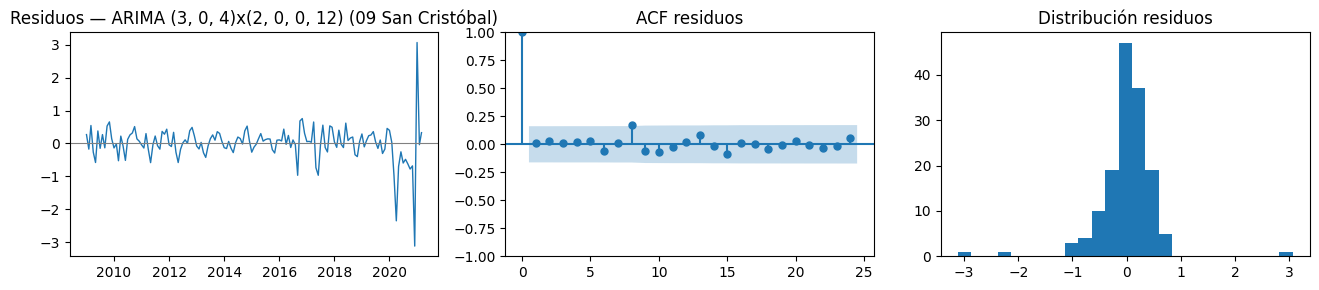

Ljung-Box (ARIMA (3, 0, 4)x(2, 0, 0, 12) (09 San Cristóbal)):


,lb_stat,lb_pvalue
12,6.890388,0.864771
24,10.814399,0.990275


16:25:29 - cmdstanpy - INFO - Chain [1] start processing
16:25:29 - cmdstanpy - INFO - Chain [1] done processing


  -> Residuos compatibles con ruido blanco (no autocorrelación).


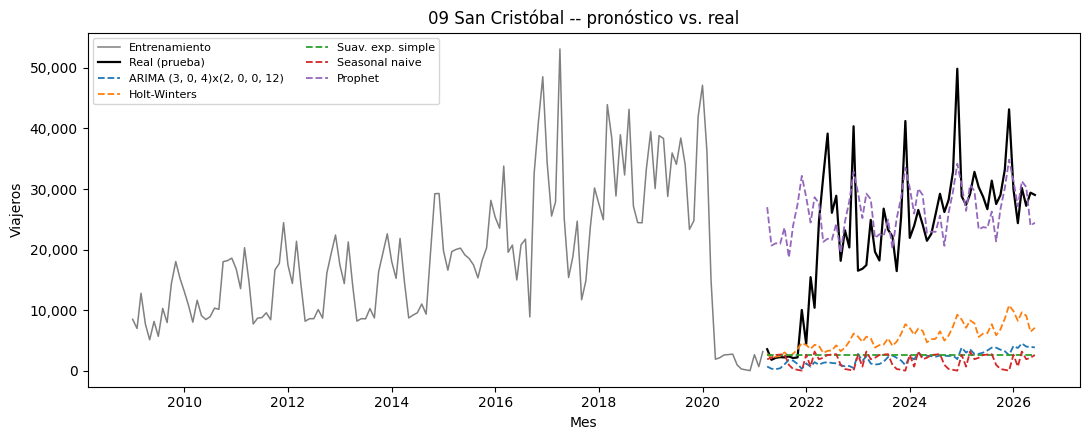

,modelo,MAE,RMSE,AIC,BIC
0,Prophet,"7,723","10,437",nan,nan
1,Holt-Winters,"17,583","19,905","2,584.1","2,632.0"
2,Suav. exp. simple,"20,483","23,091","2,613.0","2,619.0"
3,"ARIMA (3, 0, 4)x(2, 0, 0, 12)","20,932","23,381",260.0,292.9
4,Seasonal naive,"21,408","24,053",nan,nan


Mejor modelo para 09 San Cristóbal: Prophet  (MAE=7,723, RMSE=10,437)


In [4]:
train_sc, test_sc = cargar("frontera_san_cristobal")
resultado_sc = tsu.analizar_serie_completa("09 San Cristóbal", train_sc, test_sc, periodo=12)


## 4. Resumen comparativo de la categoría (insumo para el ejercicio 5)

In [5]:
resumen = pd.DataFrame([
    {"frontera": r["nombre"], "d": r["d"], "D": r["D"], "descomposición": r["modelo_decomp"],
     "mejor_modelo": r["mejor_modelo"], "MAE": r["mejor_mae"], "RMSE": r["mejor_rmse"],
     "corr_nivel_std": r["corr_nivel_std"]}
    for r in [resultado_au, resultado_vn, resultado_sc]
])
display(resumen.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "corr_nivel_std": "{:.2f}"}))

resumen.to_csv("../data/processed/resumen_fronteras.csv", index=False)
print("Guardado: data/processed/resumen_fronteras.csv (insumo para 06_analisis_comparativo.ipynb)")


,frontera,d,D,descomposición,mejor_modelo,MAE,RMSE,corr_nivel_std
0,01 La Aurora,1,1,multiplicative,Holt-Winters,"25,156","30,237",0.89
1,07 Valle Nuevo,1,1,multiplicative,Prophet,"15,219","21,764",0.31
2,09 San Cristóbal,2,1,multiplicative,Prophet,"7,723","10,437",0.53


Guardado: data/processed/resumen_fronteras.csv (insumo para 06_analisis_comparativo.ipynb)


## 5. Conclusiones de la categoría

- **01 La Aurora** es la única frontera **aérea** de las tres (las otras dos
  son pasos terrestres), por lo que se espera que su perfil de estacionalidad
  y su reacción a la pandemia difieran más marcadamente de Valle Nuevo y San
  Cristóbal (el cierre de fronteras aéreas en 2020 fue más severo y prolongado
  que el de los pasos terrestres regionales).
- La tabla de la sección 4 resume, para esta ejecución concreta, el orden de
  diferenciación y el modelo ganador de cada frontera.
- Estas diferencias se retoman de forma explícitamente comparativa en
  `06_analisis_comparativo.ipynb` (ejercicio 5).
